# Battery Storage Simulation for a Solar Plant

**Question:** if a solar plant is limited by its grid connection, how much clean energy is wasted at midday, and how much of it can a battery recover and shift to the evening?

**Why it matters:** high shares of solar create midday surplus and evening shortfall. Storage is one of the main flexibility tools for integrating renewables, but its value depends on size and operating rules. This notebook quantifies that trade-off on real plant data.

**Data:** [Solar Power Generation Data (Kaggle)](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data): Plant 1, India, 34 days, 15-minute resolution. Only the plant's total AC power is used here.

**Important:** the battery, the grid limit and the evening window are **simulation assumptions, not measured data** (see the table below). The results show how storage would behave under those assumptions.

**Approach:**
1. Build the plant's total power series from the inverter data.
2. Define a grid export limit and measure the energy that would be curtailed (wasted) without storage.
3. Simulate a battery with a simple rule: charge from the surplus above the limit, discharge in the evening.
4. Compare scenarios and test how battery size changes the outcome.

## Assumptions

| Assumption | Value | Reason |
|---|---|---|
| Grid export limit | 75% of the plant's peak observed output | Simple proxy for a congested connection. Real limits vary by site |
| Battery size (main scenario) | 20 MWh, 8 MW (2.5 hours at full power) | Illustrative size, varied in the sensitivity analysis |
| Round-trip efficiency | 90% | Typical order of magnitude for lithium-ion systems |
| Minimum state of charge | 10% | Avoids full discharge |
| Evening window | 18:00 to 22:00 | Proxy for high-demand hours. No electricity prices are used |
| Operating rule | Charge only from power above the grid limit. Discharge only inside the evening window | Simple and transparent, not an optimised schedule |

## 1. Imports and settings

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

STEP_MINUTES = 15
DT_H = STEP_MINUTES / 60            # hours per time step

# Simulation assumptions (see the table above)
CAP_FRACTION = 0.75                 # grid limit as a fraction of peak output
BATTERY_MWH = 20                    # main scenario battery energy capacity
DURATION_H = 2.5                    # hours at full power -> 20 MWh / 2.5 h = 8 MW
ROUND_TRIP_EFF = 0.90
SOC_MIN_FRAC = 0.10
PEAK_START, PEAK_END = 18, 22       # evening window (hours)

plt.rcParams["figure.figsize"] = (12, 4)

## 2. Load the plant's total power

The generation file has one row per inverter per timestamp. Summing AC power over all inverters gives the plant output. Short gaps (up to 1 hour) are filled by interpolation, as in the forecasting project.

In [2]:
DATA_ROOT = "/kaggle/input"
gen_file = glob.glob(f"{DATA_ROOT}/**/Plant_1_Generation_Data.csv", recursive=True)[0]
gen = pd.read_csv(gen_file)
gen["DATE_TIME"] = pd.to_datetime(gen["DATE_TIME"], format="%d-%m-%Y %H:%M")

solar = gen.groupby("DATE_TIME")["AC_POWER"].sum()

full_index = pd.date_range(solar.index.min(), solar.index.max(), freq=f"{STEP_MINUTES}min")
print(f"Rows: {len(solar)} | Expected: {len(full_index)} | Missing timestamps: {len(full_index) - len(solar)}")

solar = solar.reindex(full_index).interpolate(limit=4)
print("NaNs left after interpolation (set to 0):", int(solar.isna().sum()))
solar = solar.fillna(0).clip(lower=0)

print(f"Days: {len(solar) / 96:.1f} | Peak output: {solar.max():,.0f} kW | Total energy: {solar.sum() * DT_H / 1000:,.0f} MWh")

Rows: 3158 | Expected: 3264 | Missing timestamps: 106
NaNs left after interpolation (set to 0): 79
Days: 34.0 | Peak output: 29,150 kW | Total energy: 5,328 MWh


## 3. Grid limit and curtailment without storage

**Curtailment** is solar energy that is available but cannot be delivered because the grid connection is full. Without a battery, everything above the limit is wasted.

In [3]:
GRID_CAP_KW = CAP_FRACTION * solar.max()
print(f"Assumed grid export limit: {GRID_CAP_KW:,.0f} kW")

curtailed_no_batt = (solar - GRID_CAP_KW).clip(lower=0)
share = curtailed_no_batt.sum() / solar.sum() * 100
print(f"Curtailed without storage: {curtailed_no_batt.sum() * DT_H / 1000:,.0f} MWh ({share:.1f}% of generation)")

Assumed grid export limit: 21,863 kW
Curtailed without storage: 187 MWh (3.5% of generation)


## 4. Battery simulation

At every 15-minute step:
1. **Charge:** if solar output exceeds the grid limit, the surplus charges the battery (limited by power rating and free capacity). Anything that cannot be stored is curtailed.
2. **Discharge:** inside the evening window, the battery discharges at up to its power rating, limited by the remaining stored energy and by the grid limit.
3. Efficiency losses are applied on both charging and discharging (each side uses the square root of the round-trip efficiency).

In [4]:
def simulate(solar_kw, hours, capacity_kwh, power_kw, cap_kw,
             round_trip_eff=ROUND_TRIP_EFF, soc_min_frac=SOC_MIN_FRAC,
             peak=(PEAK_START, PEAK_END)):
    eta = np.sqrt(round_trip_eff)              # one-way efficiency
    soc_min, soc_max = soc_min_frac * capacity_kwh, capacity_kwh
    soc = soc_min                              # start at the minimum state of charge

    n = len(solar_kw)
    charge_in = np.zeros(n)                    # kW taken from solar into the battery
    discharge_out = np.zeros(n)                # kW delivered to the grid from the battery
    curtailed = np.zeros(n)
    export_direct = np.zeros(n)
    soc_series = np.zeros(n)

    for i in range(n):
        p = solar_kw[i]
        export_direct[i] = min(p, cap_kw)
        excess = max(p - cap_kw, 0.0)

        # charge from the surplus
        room_kwh = soc_max - soc
        c = min(excess, power_kw, room_kwh / (DT_H * eta))
        c = max(c, 0.0)
        soc += c * DT_H * eta
        charge_in[i] = c
        curtailed[i] = excess - c

        # discharge in the evening window
        if peak[0] <= hours[i] < peak[1]:
            avail_kw = max(soc - soc_min, 0.0) * eta / DT_H
            d = min(power_kw, avail_kw, max(cap_kw - export_direct[i], 0.0))
            soc -= d * DT_H / eta
            discharge_out[i] = d

        soc_series[i] = soc

    return pd.DataFrame({
        "solar": solar_kw, "export_direct": export_direct, "charge_in": charge_in,
        "discharge_out": discharge_out, "curtailed": curtailed,
        "export_total": export_direct + discharge_out, "soc_kwh": soc_series,
    })

hours = (solar.index.hour + solar.index.minute / 60).values
solar_kw = solar.values

## 5. Scenarios

Two scenarios are compared: **no battery** and the **main battery** (20 MWh, 8 MW).

In [5]:
def summarise(name, sim, capacity_kwh):
    mwh = lambda s: s.sum() * DT_H / 1000
    out = {
        "Scenario": name,
        "Curtailed (MWh)": mwh(sim["curtailed"]),
        "Curtailed (% of generation)": sim["curtailed"].sum() / sim["solar"].sum() * 100,
        "Evening energy from battery (MWh)": mwh(sim["discharge_out"]),
        "Equivalent full cycles": (sim["discharge_out"].sum() * DT_H / capacity_kwh) if capacity_kwh else 0.0,
    }
    return out

cap_kwh = BATTERY_MWH * 1000
pow_kw = cap_kwh / DURATION_H

sim_none = simulate(solar_kw, hours, 0, 0, GRID_CAP_KW)
sim_batt = simulate(solar_kw, hours, cap_kwh, pow_kw, GRID_CAP_KW)

table = pd.DataFrame([
    summarise("No battery", sim_none, 0),
    summarise(f"Battery {BATTERY_MWH} MWh / {pow_kw/1000:.0f} MW", sim_batt, cap_kwh),
]).set_index("Scenario").round(1)
table

,Curtailed (MWh),Curtailed (% of generation),Evening energy from battery (MWh),Equivalent full cycles
Scenario,,,,
No battery,187.1,3.5,0.0,0.0
Battery 20 MWh / 8 MW,0.0,0.0,168.4,8.4


In [6]:
base = sim_none["curtailed"].sum()
recovered = (base - sim_batt["curtailed"].sum()) / base * 100
print(f"Curtailed energy recovered by the battery: {recovered:.1f}%")

Curtailed energy recovered by the battery: 100.0%


### Sanity checks

Before trusting the results, the simulation must respect basic physical rules: the state of charge stays within limits, nothing is exported above the grid limit, and energy is conserved (solar = direct export + charging + curtailment).

In [7]:
tol = 1e-6
eta = np.sqrt(ROUND_TRIP_EFF)

assert (sim_batt["soc_kwh"] <= cap_kwh + tol).all(), "SOC above capacity"
assert (sim_batt["soc_kwh"] >= SOC_MIN_FRAC * cap_kwh - tol).all(), "SOC below minimum"
assert (sim_batt["export_total"] <= GRID_CAP_KW + tol).all(), "Export above grid limit"
assert (sim_batt["curtailed"] >= -tol).all(), "Negative curtailment"

balance = sim_batt["solar"] - (sim_batt["export_direct"] + sim_batt["charge_in"] + sim_batt["curtailed"])
assert balance.abs().max() < 1e-6, "Solar energy balance broken"

soc_end_expected = (SOC_MIN_FRAC * cap_kwh
                    + sim_batt["charge_in"].sum() * DT_H * eta
                    - sim_batt["discharge_out"].sum() * DT_H / eta)
assert abs(sim_batt["soc_kwh"].iloc[-1] - soc_end_expected) < 1e-3, "Battery energy balance broken"

print("All checks passed.")

All checks passed.


## 6. What it looks like

Three consecutive days starting from the day with the most curtailment. The top chart shows what reaches the grid with and without the battery, and the bottom chart shows the battery's state of charge.

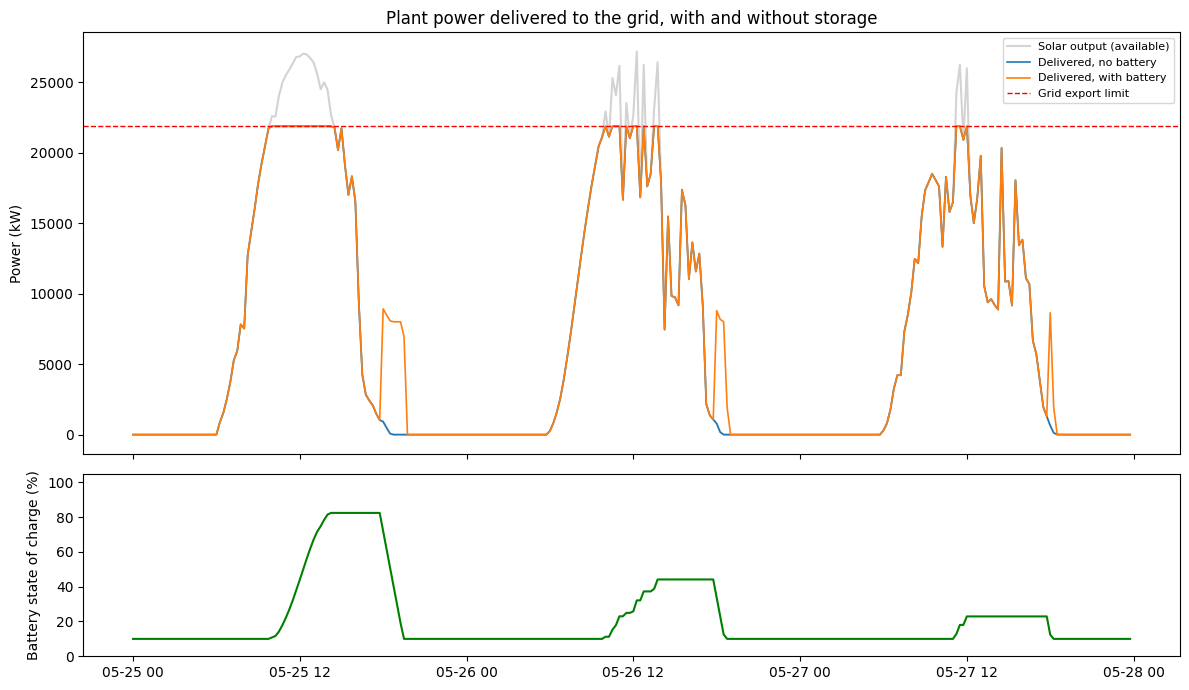

In [8]:
daily_curt = sim_none["curtailed"].groupby(solar.index.date).sum()
start_day = pd.Timestamp(daily_curt.idxmax())
end_day = min(start_day + pd.Timedelta(days=3), solar.index.max())
window = (solar.index >= start_day) & (solar.index < end_day)
t = solar.index[window]

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax[0].plot(t, sim_none["solar"][window], color="lightgray", lw=1.5, label="Solar output (available)")
ax[0].plot(t, sim_none["export_total"][window], lw=1.2, label="Delivered, no battery")
ax[0].plot(t, sim_batt["export_total"][window], lw=1.2, label="Delivered, with battery")
ax[0].axhline(GRID_CAP_KW, color="red", ls="--", lw=1, label="Grid export limit")
ax[0].set_ylabel("Power (kW)")
ax[0].set_title("Plant power delivered to the grid, with and without storage")
ax[0].legend(loc="upper right", fontsize=8)

ax[1].plot(t, sim_batt["soc_kwh"][window] / cap_kwh * 100, color="green")
ax[1].set_ylabel("Battery state of charge (%)")
ax[1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig("storage_scenario.png", dpi=150)
plt.show()

### Interpretation

- On the first day shown, solar output rises well above the assumed grid limit. Without storage the excess is lost (the flat top at the limit). With the battery, the excess charges it (state of charge reaches about 80%) and is delivered shortly after solar output drops, at the battery's power limit.
- On days with less surplus the battery charges less, so stored energy follows the amount of curtailed energy rather than a fixed schedule.
- Energy delivered in the evening is lower than the energy absorbed because of the 90% round-trip efficiency.

## 7. How big should the battery be?

The same simulation is repeated for different battery sizes (the power rating scales with size, keeping the 2.5-hour duration). Larger batteries recover more curtailed energy, but each extra MWh usually recovers less than the one before.

In [9]:
sizes_mwh = [0, 5, 10, 20, 30, 40, 60]
days = len(solar) / 96
rows = []
for s in sizes_mwh:
    ckwh = s * 1000
    sim = simulate(solar_kw, hours, ckwh, ckwh / DURATION_H, GRID_CAP_KW)
    rows.append({
        "Battery (MWh)": s,
        "Curtailed (MWh)": sim["curtailed"].sum() * DT_H / 1000,
        "Recovered (%)": (base - sim["curtailed"].sum()) / base * 100,
        "Evening energy (MWh/day)": sim["discharge_out"].sum() * DT_H / 1000 / days,
        "Full cycles": (sim["discharge_out"].sum() * DT_H / ckwh) if ckwh else 0.0,
    })
sens = pd.DataFrame(rows).set_index("Battery (MWh)").round(1)
sens

,Curtailed (MWh),Recovered (%),Evening energy (MWh/day),Full cycles
Battery (MWh),,,,
0,187.1,0.0,0.0,0.0
5,94.3,49.6,2.5,16.7
10,30.9,83.5,4.1,14.1
20,0.0,100.0,5.0,8.4
30,0.0,100.0,5.0,5.6
40,0.0,100.0,5.0,4.2
60,0.0,100.0,5.0,2.8


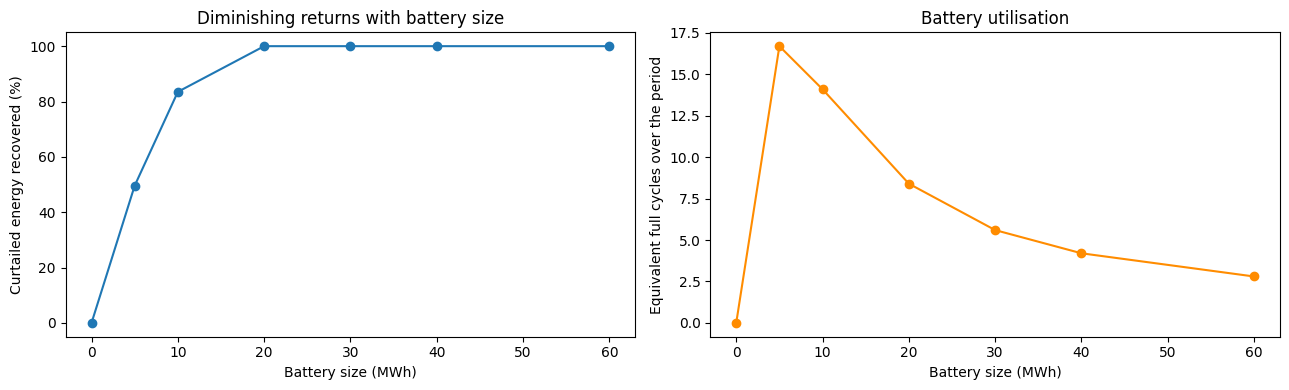

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(sens.index, sens["Recovered (%)"], marker="o")
ax[0].set_xlabel("Battery size (MWh)")
ax[0].set_ylabel("Curtailed energy recovered (%)")
ax[0].set_title("Diminishing returns with battery size")

ax[1].plot(sens.index, sens["Full cycles"], marker="o", color="darkorange")
ax[1].set_xlabel("Battery size (MWh)")
ax[1].set_ylabel("Equivalent full cycles over the period")
ax[1].set_title("Battery utilisation")

plt.tight_layout()
plt.savefig("battery_size_sensitivity.png", dpi=150)
plt.show()

### Interpretation

- Without storage, **187 MWh (3.5% of generation)** is curtailed under the assumed grid limit.
- Returns diminish quickly: a 5 MWh battery recovers about half (49.6%), 10 MWh about 84% (83.5%), and 20 MWh recovers all of it. Beyond 20 MWh nothing more can be recovered, because the battery only charges from the surplus above the limit and there is nothing left to store.
- Larger batteries are used less: equivalent full cycles over the period fall from about 17 (5 MWh) to about 3 (60 MWh). Oversizing adds idle capacity.
- Evening energy levels off at 5.0 MWh per day, about 90% of the daily curtailed energy (187 MWh over 34 days is about 5.5 MWh per day), consistent with the 90% round-trip efficiency.
- Within this setup, a 10 to 20 MWh battery looks like the sensible range. The 8 MW power rating also covers the largest instantaneous surplus (about 7 MW).
- These results depend strongly on the assumed grid limit. A lower limit would mean more curtailment and a stronger case for storage.

## 8. Summary of the numbers

In [11]:
best_small = sens.index[sens["Recovered (%)"] >= 0.9 * sens["Recovered (%)"].max()][0]
print(f"Grid limit assumed: {GRID_CAP_KW:,.0f} kW ({CAP_FRACTION:.0%} of peak output)")
print(f"Curtailed without storage: {base * DT_H / 1000:,.0f} MWh "
      f"({base / solar.sum() * 100:.1f}% of generation)")
print(f"Main battery ({BATTERY_MWH} MWh / {pow_kw / 1000:.0f} MW): recovers {recovered:.1f}% of curtailed energy "
      f"and delivers {sim_batt['discharge_out'].sum() * DT_H / 1000 / days:.1f} MWh per day in the evening window")
print(f"Smallest tested size reaching 90% of the best recovery: {best_small} MWh")

Grid limit assumed: 21,863 kW (75% of peak output)
Curtailed without storage: 187 MWh (3.5% of generation)
Main battery (20 MWh / 8 MW): recovers 100.0% of curtailed energy and delivers 5.0 MWh per day in the evening window
Smallest tested size reaching 90% of the best recovery: 20 MWh


## 9. Limitations and next steps

- **Assumed, not measured:** grid limit, battery size, efficiency and the evening window are assumptions. Real projects depend on actual interconnection limits, equipment specifications and market prices.
- **No economics:** the notebook counts energy, not money. A real study would add electricity prices, battery costs and degradation.
- **Simple rule, not an optimised schedule:** the battery charges only from the surplus and discharges at maximum power in a fixed window. An optimiser could do better.
- **Short data:** 34 days from one plant in one season. Results are indicative.
- **Next steps:** use the solar forecast from the [forecasting project](https://github.com/eman774/solar-power-forecasting) to plan charging and discharging ahead of time; add time-varying prices; test Plant 2.